# Student placement prediction

This notebook explores the supplied training data, checks suspicious fields, compares classifiers with a stratified holdout, and refits the selected pipeline on all labeled rows. All imputers, encoders, and scalers are inside sklearn pipelines, so holdout data is not used to fit preprocessing. Run from this folder or the submission root.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split, StratifiedKFold, TunedThresholdClassifierCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
try:
    from IPython.display import display
except ImportError:
    display = print

cwd = Path.cwd()
if (cwd / 'data' / 'train.csv').exists():
    HERE = cwd
elif (cwd / 'placement' / 'data' / 'train.csv').exists():
    HERE = cwd / 'placement'
else:
    raise FileNotFoundError('Run from placement/ or the submission root.')
DATA_PATH = HERE / 'data' / 'train.csv'
df = pd.read_csv(DATA_PATH)
SEED = 42
TARGET = 'placed'
display(df.head())
print('Data file:', DATA_PATH.resolve())

,student_id,department,city_tier,cgpa,backlogs,internship_months,coding_score,projects,workshops,status_code,placed
0,S00802,CSE,2,7.00,1.0,5,56.6,5,4,NaN,1
1,S02107,CSE,3,8.06,1.0,4,29.9,1,3,1.0,1
2,S01945,CSE,3,7.92,0.0,0,52.4,2,2,0.0,0
3,S01956,MECH,2,7.49,1.0,1,37.3,1,1,0.0,0
4,S01828,CSE,2,8.80,NaN,0,82.2,2,3,1.0,1


Data file: F:\GoML Engineer\candidate_pack\candidate_pack\placement\data\train.csv


## Dataset and data quality

The documentation defines `placed` as the target and gives the meaning of the other columns. Missing values occur in numeric features and `status_code`; the fitted pipeline imputes numeric values from each training fold only. Check target balance and duplicate rows before modelling.

Rows, columns: (2500, 11)


,dtype
student_id,str
department,str
city_tier,int64
cgpa,float64
backlogs,float64
internship_months,int64
coding_score,float64
projects,int64
workshops,int64
status_code,float64


,missing
student_id,0
department,0
city_tier,0
cgpa,118
backlogs,168
internship_months,0
coding_score,525
projects,0
workshops,0
status_code,113


Exact duplicate rows:

 0
Duplicate student IDs: 0


,count
placed,
not placed,1798
placed,702


,percent
placed,
not placed,71.92
placed,28.08


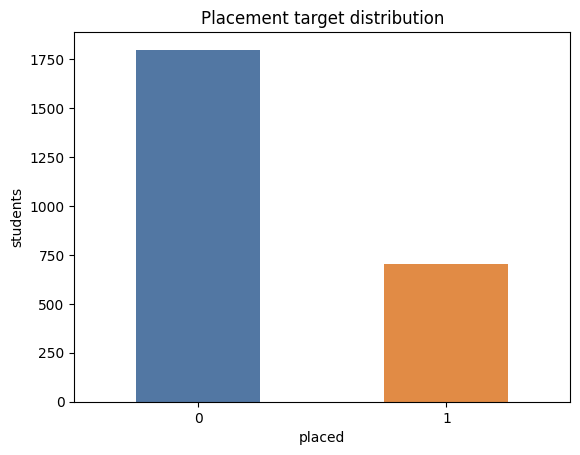

In [2]:
print('Rows, columns:', df.shape)
display(df.dtypes.rename('dtype').to_frame())
display(df.isna().sum().rename('missing').to_frame())
print('Exact duplicate rows:', int(df.duplicated().sum()))
print('Duplicate student IDs:', int(df.student_id.duplicated().sum()))
display(df[TARGET].value_counts().sort_index().rename(index={0:'not placed', 1:'placed'}).to_frame('count'))
display((df[TARGET].value_counts(normalize=True).sort_index()*100).rename(index={0:'not placed', 1:'placed'}).to_frame('percent'))
ax = df[TARGET].value_counts().sort_index().plot.bar(color=['#5277a3','#e18b45'], rot=0)
ax.set(title='Placement target distribution', xlabel='placed', ylabel='students'); plt.show()

## Feature distributions and target relationships

The plots show the observed ranges and missingness patterns. These are descriptive; they do not imply causal effects.

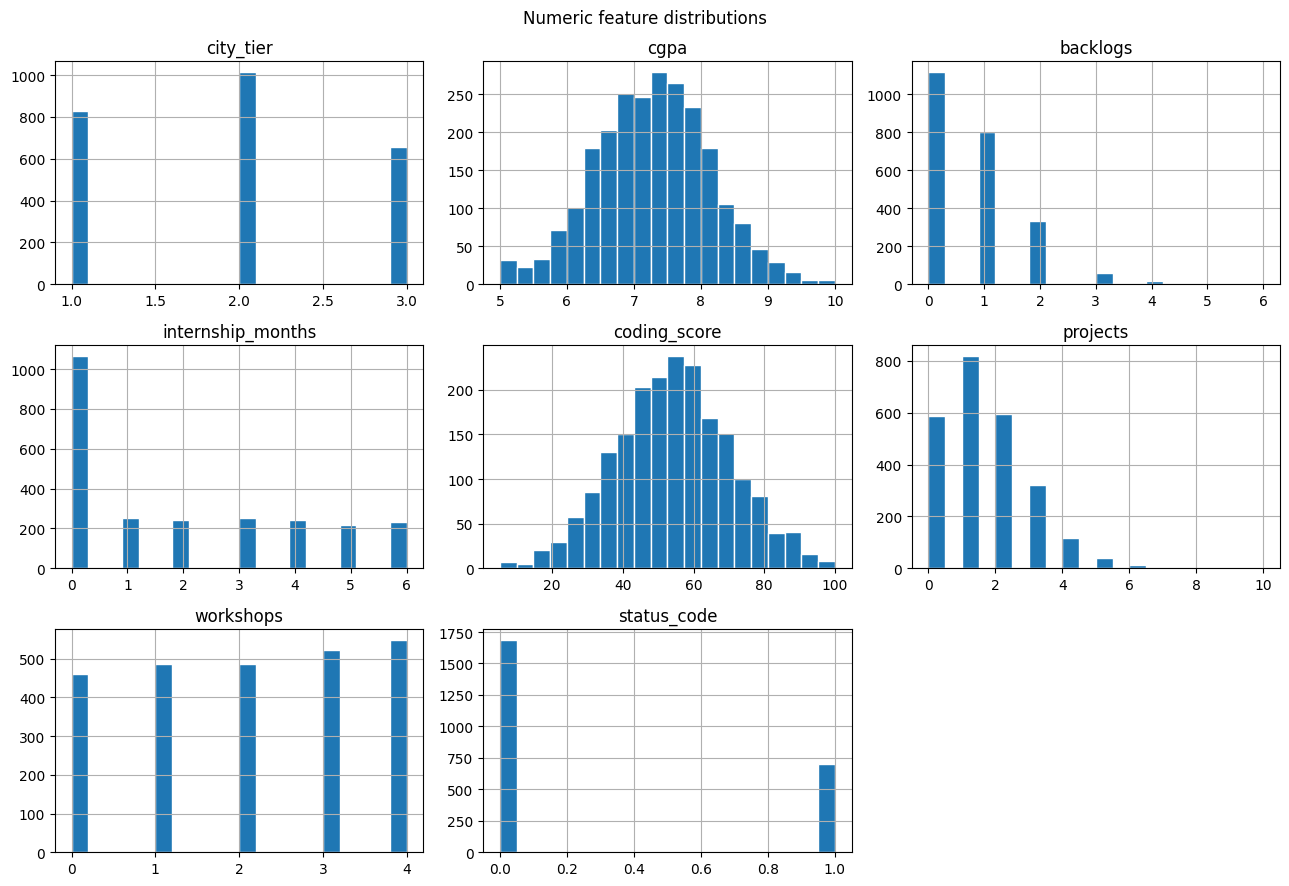

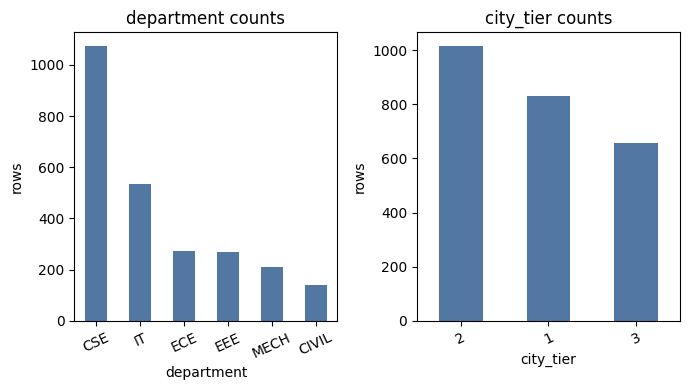

,count,mean,median
placed,,,
not placed,1798,1.920467,2.000000
placed,702,1.954416,2.000000


,count,mean,median
placed,,,
not placed,1721,7.110959,7.110000
placed,661,7.700484,7.700000


,count,mean,median
placed,,,
not placed,1680,0.834524,1.000000
placed,652,0.510736,0.000000


,count,mean,median
placed,,,
not placed,1798,1.822024,1.000000
placed,702,2.367521,2.000000


,count,mean,median
placed,,,
not placed,1417,51.296048,51.100000
placed,558,61.851075,61.300000


,count,mean,median
placed,,,
not placed,1798,1.392102,1.000000
placed,702,1.814815,2.000000


,count,mean,median
placed,,,
not placed,1798,2.043382,2.000000
placed,702,2.193732,2.000000


,count,mean,median
placed,,,
not placed,1709,0.032183,0.000000
placed,678,0.951327,1.000000


placed,not placed,placed
department,,
CIVIL,86.4%,13.6%
CSE,61.6%,38.4%
ECE,81.3%,18.7%
EEE,79.2%,20.8%
IT,75.5%,24.5%
MECH,84.2%,15.8%


In [3]:
numeric_all = df.select_dtypes(include='number').columns.drop(TARGET)
df[numeric_all].hist(figsize=(13,9), bins=20, edgecolor='white'); plt.suptitle('Numeric feature distributions'); plt.tight_layout(); plt.show()
categorical_all = ['department', 'city_tier']
fig, axes = plt.subplots(1, len(categorical_all), figsize=(7,4))
for ax, col in zip(np.atleast_1d(axes), categorical_all):
    df[col].value_counts(dropna=False).plot.bar(ax=ax, color='#5277a3')
    ax.set(title=f'{col} counts', xlabel=col, ylabel='rows')
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()
for col in numeric_all:
    display(df.groupby(TARGET)[col].agg(['count','mean','median']).rename(index={0:'not placed',1:'placed'}).style.set_caption(f'{col} by outcome'))
display(pd.crosstab(df.department, df[TARGET], normalize='index').rename(columns={0:'not placed',1:'placed'}).style.format('{:.1%}').set_caption('Department outcome shares'))

## Correlations and leakage investigation

`student_id` is an identifier; it is not used by the final model. Its uniqueness and lack of documented predictive semantics make memorization/generalization unsafe. `status_code` is documented only as a field on the portal; no definition or timing is supplied. Its unusually strong association with the target makes it a leakage risk, so it is excluded pending confirmation that it is available before placement decisions. The comparison below quantifies the score change but does not treat that gain as evidence that the field is legitimate.

status_code value counts (including missing):


,rows
status_code,
0.0,1687
1.0,700
NaN,113


Placement rate by status_code (descriptive only):


,count,mean
status_code,,
0.0,1687,0.019561
1.0,700,0.921429
NaN,113,0.212389


student_id numeric suffix / target correlation (diagnostic only): -0.0118


,city_tier,cgpa,backlogs,internship_months,coding_score,projects,workshops,status_code,placed
city_tier,1.00,0.01,-0.00,0.04,0.01,-0.00,0.00,0.02,0.02
cgpa,0.01,1.00,-0.21,-0.01,0.55,0.19,0.02,0.28,0.31
backlogs,-0.00,-0.21,1.00,-0.03,-0.17,-0.07,0.01,-0.16,-0.17
internship_months,0.04,-0.01,-0.03,1.00,0.02,0.02,-0.02,0.10,0.11
coding_score,0.01,0.55,-0.17,0.02,1.00,0.11,0.05,0.26,0.29
projects,-0.00,0.19,-0.07,0.02,0.11,1.00,-0.01,0.13,0.15
workshops,0.00,0.02,0.01,-0.02,0.05,-0.01,1.00,0.04,0.05
status_code,0.02,0.28,-0.16,0.10,0.26,0.13,0.04,1.00,0.91
placed,0.02,0.31,-0.17,0.11,0.29,0.15,0.05,0.91,1.00


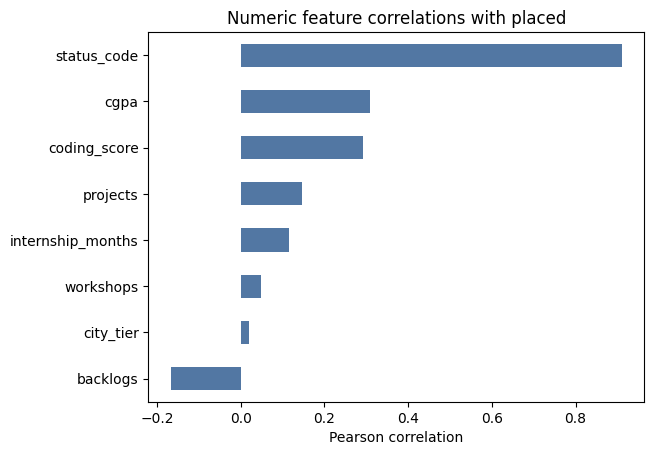

In [4]:
print('status_code value counts (including missing):')
display(df.status_code.value_counts(dropna=False).sort_index().to_frame('rows'))
print('Placement rate by status_code (descriptive only):')
display(df.groupby('status_code', dropna=False)[TARGET].agg(['count','mean']))
id_numeric = pd.to_numeric(df.student_id.astype(str).str.extract(r'(\d+)$')[0], errors='coerce')
print('student_id numeric suffix / target correlation (diagnostic only):', round(id_numeric.corr(df[TARGET]), 4))
corr_cols = list(numeric_all) + [TARGET]
display(df[corr_cols].corr(numeric_only=True).style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1).format('{:.2f}'))
ax = df[corr_cols].corr(numeric_only=True)[TARGET].drop(TARGET).sort_values().plot.barh(color='#5277a3')
ax.set(title='Numeric feature correlations with placed', xlabel='Pearson correlation'); plt.show()

## Validation and model comparison

Use one stratified 80/20 split (seed 42) for every candidate. Compare regularized logistic regression (C=0.3 and C=1.0), random forest, extra trees, and gradient boosting. Select the positive-class F1 threshold on validation predictions only. Accuracy is reported at the default and selected thresholds as well. The fixed-holdout threshold and metrics are model-selection estimates because the labels were used to select the threshold; nested cross-validation provides a less biased view. The validation partition is never used to fit imputers, encoding, or scaling. `status_code` and `student_id` are omitted from all final candidates.

In [ ]:
FEATURES = ['department','city_tier','cgpa','backlogs','internship_months','coding_score','projects','workshops']
def make_pipeline(estimator, features=FEATURES):
    numeric = [c for c in features if c != 'department' and pd.api.types.is_numeric_dtype(df[c])]
    categorical = [c for c in features if c not in numeric]
    prep = ColumnTransformer([
        ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric),
        ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical),
    ])
    return Pipeline([('preprocess', prep), ('classifier', estimator)])

y = df[TARGET].astype(int)
train_idx, valid_idx = train_test_split(np.arange(len(df)), test_size=0.2, random_state=SEED, stratify=y)
X_train, X_valid = df.iloc[train_idx][FEATURES], df.iloc[valid_idx][FEATURES]
y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]
candidates = {
    'logistic_regression_c0_3': LogisticRegression(C=0.3, max_iter=2000, class_weight='balanced', random_state=SEED),
    'logistic_regression_c1': LogisticRegression(C=1.0, max_iter=2000, class_weight='balanced', random_state=SEED),
    'random_forest': RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight='balanced_subsample', random_state=SEED, n_jobs=1),
    'extra_trees': ExtraTreesClassifier(n_estimators=400, min_samples_leaf=3, class_weight='balanced', random_state=SEED, n_jobs=1),
    'gradient_boosting': GradientBoostingClassifier(random_state=SEED),
}
thresholds = np.round(np.arange(0.10, 0.901, 0.01), 2)
results, fitted, valid_probs = {}, {}, {}
for name, estimator in candidates.items():
    model = make_pipeline(estimator).fit(X_train, y_train)
    probabilities = model.predict_proba(X_valid)[:, 1]
    threshold = max(thresholds, key=lambda t: f1_score(y_valid, probabilities >= t, zero_division=0))
    fitted[name], valid_probs[name] = model, probabilities
    results[name] = {'F1 @ 0.50': f1_score(y_valid, probabilities >= 0.5, zero_division=0), 'accuracy @ 0.50': accuracy_score(y_valid, probabilities >= 0.5), 'selected threshold': threshold, 'selected F1': f1_score(y_valid, probabilities >= threshold, zero_division=0), 'accuracy @ selected F1 threshold': accuracy_score(y_valid, probabilities >= threshold), 'precision': precision_score(y_valid, probabilities >= threshold, zero_division=0), 'recall': recall_score(y_valid, probabilities >= threshold, zero_division=0)}
results_df = pd.DataFrame(results).T.sort_values('selected F1', ascending=False)
display(results_df.style.format('{:.3f}'))
selected_name = results_df.index[0]
selected_threshold = float(results[selected_name]['selected threshold'])
print('Selected:', selected_name, '| threshold:', selected_threshold)

## Nested cross-validation for the logistic candidates

Compare C=0.3 and C=1.0 using nested CV. For each outer fold, the threshold is tuned with an inner 3-fold split; the outer fold estimates F1 and accuracy without participating in model fitting or threshold choice. A separate nested run tunes the threshold for accuracy to show the tradeoff: accuracy can rise while positive-class F1 falls. Fold scores vary, so interpret small mean differences cautiously.

In [ ]:
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
cross_validation = {}
for name in ('logistic_regression_c0_3', 'logistic_regression_c1'):
    tuned = TunedThresholdClassifierCV(
        estimator=make_pipeline(candidates[name]), scoring='f1', cv=inner_cv, thresholds=101
    )
    cv_result = cross_validate(tuned, df[FEATURES], y, cv=outer_cv,
                               scoring={'f1': 'f1', 'accuracy': 'accuracy'},
                               return_estimator=True, n_jobs=1)
    cross_validation[name] = {
        'method': 'nested 5-fold evaluation; threshold tuned for F1 in inner 3-fold CV',
        'fold_f1': [float(value) for value in cv_result['test_f1']],
        'mean_f1': float(np.mean(cv_result['test_f1'])),
        'std_f1': float(np.std(cv_result['test_f1'])),
        'fold_accuracy_at_f1_tuned_threshold': [float(value) for value in cv_result['test_accuracy']],
        'mean_accuracy_at_f1_tuned_threshold': float(np.mean(cv_result['test_accuracy'])),
        'std_accuracy_at_f1_tuned_threshold': float(np.std(cv_result['test_accuracy'])),
        'inner_selected_thresholds': [float(model.best_threshold_) for model in cv_result['estimator']],
    }
accuracy_tuned = TunedThresholdClassifierCV(
    estimator=make_pipeline(candidates['logistic_regression_c0_3']),
    scoring='accuracy', cv=inner_cv, thresholds=101
)
accuracy_cv = cross_validate(accuracy_tuned, df[FEATURES], y, cv=outer_cv,
                             scoring={'f1': 'f1', 'accuracy': 'accuracy'},
                             return_estimator=True, n_jobs=1)
accuracy_threshold_results = {
    'method': 'nested 5-fold evaluation; accuracy threshold tuned in inner 3-fold CV',
    'fold_accuracy': [float(value) for value in accuracy_cv['test_accuracy']],
    'mean_accuracy': float(np.mean(accuracy_cv['test_accuracy'])),
    'std_accuracy': float(np.std(accuracy_cv['test_accuracy'])),
    'fold_f1': [float(value) for value in accuracy_cv['test_f1']],
    'mean_f1': float(np.mean(accuracy_cv['test_f1'])),
    'std_f1': float(np.std(accuracy_cv['test_f1'])),
    'inner_selected_thresholds': [float(model.best_threshold_) for model in accuracy_cv['estimator']],
}
display(pd.DataFrame({name: {'mean_f1': value['mean_f1'],
                             'mean_accuracy_at_f1_tuned_threshold': value['mean_accuracy_at_f1_tuned_threshold'],
                             'std_f1': value['std_f1']}
                      for name, value in cross_validation.items()}).T)
display(pd.Series({'accuracy_threshold_mean_accuracy': accuracy_threshold_results['mean_accuracy'],
                   'accuracy_threshold_mean_f1': accuracy_threshold_results['mean_f1']}))

In [7]:
# Holdout-only comparison for the two questionable features. This is a risk diagnostic, not a reason by itself to include either field.
feature_checks = {'neither': FEATURES, 'student_id_only': FEATURES + ['student_id'], 'status_code_only': FEATURES + ['status_code']}
diagnostic = {}
for label, cols in feature_checks.items():
    diagnostic_model = make_pipeline(LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED), cols)
    diagnostic_model.fit(df.iloc[train_idx][cols], y.iloc[train_idx])
    p = diagnostic_model.predict_proba(df.iloc[valid_idx][cols])[:, 1]
    t = max(thresholds, key=lambda value: f1_score(y.iloc[valid_idx], p >= value, zero_division=0))
    diagnostic[label] = {'threshold': float(t), 'F1': float(f1_score(y.iloc[valid_idx], p >= t, zero_division=0))}
display(pd.DataFrame(diagnostic).T)

,threshold,F1
neither,0.59,0.576512
student_id_only,0.55,0.580645
status_code_only,0.80,0.932384


## Leakage comparison and error analysis

For context, including `status_code` produced about 0.92 F1 and 0.96 accuracy in five-fold out-of-fold experiments, versus about 0.57 F1 without it. This unusually strong result is suspicious and not a safe basis for prediction without knowing the field's timestamp/definition. The chosen model therefore accepts a lower score to avoid likely outcome-derived data. Review false positives and false negatives to understand remaining errors.

In [8]:
best_probs = valid_probs[selected_name]
best_pred = (best_probs >= selected_threshold).astype(int)
print(classification_report(y_valid, best_pred, digits=3, zero_division=0))
display(pd.DataFrame(confusion_matrix(y_valid, best_pred), index=['actual 0','actual 1'], columns=['predicted 0','predicted 1']))
error_rows = df.iloc[valid_idx][['student_id'] + FEATURES].copy()
error_rows['actual'] = y_valid.to_numpy(); error_rows['predicted'] = best_pred
error_rows['probability_placed'] = best_probs
false_positives = error_rows[(error_rows.actual == 0) & (error_rows.predicted == 1)]
false_negatives = error_rows[(error_rows.actual == 1) & (error_rows.predicted == 0)]
print('False positives:', len(false_positives), '| false negatives:', len(false_negatives))
display(false_positives.head(10)); display(false_negatives.head(10))

              precision    recall  f1-score   support

           0      0.836     0.836     0.836       360
           1      0.579     0.579     0.579       140

    accuracy                          0.764       500
   macro avg      0.707     0.707     0.707       500
weighted avg      0.764     0.764     0.764       500



,predicted 0,predicted 1
actual 0,301,59
actual 1,59,81


False positives: 59 | false negatives: 59


,student_id,department,city_tier,cgpa,backlogs,internship_months,coding_score,projects,workshops,actual,predicted,probability_placed
1523,S01955,CSE,2,9.05,0.0,2,77.0,4,4,0,1,0.950692
1139,S00382,CSE,1,7.14,0.0,1,66.9,2,4,0,1,0.705574
2478,S02315,CIVIL,2,8.23,0.0,6,66.8,1,2,0,1,0.613687
275,S00085,ECE,1,8.02,1.0,6,71.8,0,2,0,1,0.636986
2128,S00768,IT,2,8.29,0.0,0,92.1,3,3,0,1,0.845145
1219,S01579,CSE,1,7.77,1.0,0,64.8,3,2,0,1,0.687779
2300,S00174,CSE,3,6.80,0.0,5,57.6,3,0,0,1,0.686649
23,S02360,CSE,2,8.40,0.0,1,57.2,1,2,0,1,0.771580
2287,S00386,CSE,2,7.86,0.0,0,77.2,1,4,0,1,0.813080
875,S01415,CSE,1,7.70,0.0,1,58.0,2,0,0,1,0.656448


,student_id,department,city_tier,cgpa,backlogs,internship_months,coding_score,projects,workshops,actual,predicted,probability_placed
2388,S01188,MECH,2,7.69,1.0,6,70.8,0,4,1,0,0.504970
1709,S01394,CSE,2,7.39,1.0,0,32.4,4,4,1,0,0.499617
1230,S00948,CSE,2,6.51,0.0,0,35.1,3,2,1,0,0.364325
1921,S00002,CSE,2,6.36,0.0,0,44.4,2,1,1,0,0.347838
520,S00765,CSE,3,NaN,0.0,4,38.5,1,1,1,0,0.565696
251,S02299,CSE,2,6.62,1.0,0,27.9,2,0,1,0,0.212889
315,S01077,EEE,1,6.40,0.0,2,53.0,0,1,1,0,0.173659
75,S01702,CSE,2,7.54,1.0,0,40.2,0,0,1,0,0.353024
1305,S01566,CSE,3,NaN,2.0,0,61.8,2,4,1,0,0.562293
2435,S00256,IT,3,7.35,0.0,3,51.4,2,1,1,0,0.501013


## Final model and inference artifact

Regularized logistic regression (C=0.3) remains the selected model: it has the strongest F1/accuracy combination on the fixed holdout at the F1-selected threshold. The holdout result is potentially optimistic because threshold selection and scoring use the same split. Nested cross-validation estimates mean F1 0.5667 for F1-tuned thresholds, with mean accuracy 0.6812; when accuracy is optimized instead, nested mean accuracy is 0.7516 while mean F1 falls to 0.4000. This documents the metric tradeoff rather than claiming a free gain. The final pipeline is refitted on all labeled training rows and saved with feature names and validation metadata.

In [ ]:
import joblib
final_model = make_pipeline(candidates[selected_name]).fit(df[FEATURES], y)
joblib.dump(final_model, HERE / 'placement_model.joblib')
config = {
    'features': FEATURES, 'threshold': selected_threshold, 'random_seed': SEED,
    'validation': {'method':'stratified 80/20 holdout; threshold selected on this split','test_size':0.2,'seed':SEED,'majority_class_accuracy_baseline':float(max(y.mean(),1-y.mean()))},
    'selected_model': selected_name, 'validation_results': results,
    'nested_cross_validation': cross_validation, 'nested_accuracy_threshold_comparison': accuracy_threshold_results, 'training_rows': int(len(df)),
    'excluded_features': {
        'student_id': 'Identifier with no defensible predictive meaning; excluded to avoid memorization.',
        'status_code': 'Undocumented portal field, unavailable semantics/timing; near-target separation suggests potential outcome leakage.'}
}
(HERE / 'model_config.json').write_text(json.dumps(config, indent=2) + '\n', encoding='utf-8')
print('Saved:', (HERE / 'placement_model.joblib').resolve())
print('Threshold:', selected_threshold, '| validation F1:', results[selected_name]['selected F1'])

Saved: F:\GoML Engineer\candidate_pack\candidate_pack\placement\placement_model.joblib
Threshold: 0.59 | validation F1: 0.5785714285714286
